#### Que- Explain ROC Curve, how its built, its end points, how its end points are found

An **ROC (Receiver Operating Characteristic) Curve** is a graphical plot that evaluates how well a binary classification model (like predicting Sick vs. Healthy) separates two classes across all possible probability decision thresholds.

## 1. The Core Intuition

Imagine you are a doctor testing a new blood test to detect a disease. The test gives a continuous probability score between 0% and 100%.

To declare someone "Sick", you must pick a cutoff threshold $T$:

- If the score $\ge T$, classify as **Positive (Sick)**.
- If the score $\lt T$, classify as **Negative (Healthy)**.

If you set $T$ extremely high, you'll rarely accuse healthy people by accident, but you will miss actual sick patients. If you set $T$ extremely low, you catch all sick patients, but you falsely flag many healthy ones.

The ROC curve visualizes this exact trade-off between **True Positives** (what you want to catch) and **False Positives** (false alarms) as $T$ moves from $\infty$ down to $0$.

## 2. The Mathematical Definitions

An ROC curve plots **True Positive Rate (TPR)** on the Y-axis against **False Positive Rate (FPR)** on the X-axis.

$$
\text{TPR (Sensitivity)} = \frac{\text{True Positives (TP)}}{\text{Total Actual Positives (TP + FN)}}
$$

$$
\text{FPR (1 - Specificity)} = \frac{\text{False Positives (FP)}}{\text{Total Actual Negatives (FP + TN)}}
$$

Both metrics range from $0.0$ to $1.0$.

## 3. Step-by-Step Numerical Example (How It's Built)

Suppose we have 5 patients: 3 actually have the disease ($\text{P}_1, \text{P}_2, \text{P}_3$) and 2 are healthy ($\text{N}_1, \text{N}_2$). Our model assigns them predicted probabilities of having the disease:

| Patient | True Label | Predicted Probability ($p$) |
| --- | --- | --- |
| $\text{P}_1$ | **1 (Sick)** | 0.90 |
| $\text{P}_2$ | **1 (Sick)** | 0.75 |
| $\text{N}_1$ | **0 (Healthy)** | 0.60 |
| $\text{P}_3$ | **1 (Sick)** | 0.40 |
| $\text{N}_2$ | **0 (Healthy)** | 0.10 |

Total Actual Positives ($P$) = 3

Total Actual Negatives ($N$) = 2

To construct the ROC curve, we sweep the decision threshold $T$ through all values:

1. **Threshold $T \gt 0.90$ (e.g., $T = 1.0$)**
- Classifications: All predicted 0.
- $\text{TP} = 0$, $\text{FP} = 0$.
- $\text{TPR} = 0/3 = \mathbf{0.0}$, $\text{FPR} = 0/2 = \mathbf{0.0}$.
- **Point on graph:** $(0, 0)$
2. **Threshold $T = 0.70$**
- Classifications: $\text{P}_1, \text{P}_2$ predicted 1. Rest predicted 0.
- $\text{TP} = 2$, $\text{FP} = 0$.
- $\text{TPR} = 2/3 \approx \mathbf{0.67}$, $\text{FPR} = 0/2 = \mathbf{0.0}$.
- **Point on graph:** $(0, 0.67)$
3. **Threshold $T = 0.50$**
- Classifications: $\text{P}_1, \text{P}_2, \text{N}_1$ predicted 1.
- $\text{TP} = 2$, $\text{FP} = 1$.
- $\text{TPR} = 2/3 \approx \mathbf{0.67}$, $\text{FPR} = 1/2 = \mathbf{0.50}$.
- **Point on graph:** $(0.50, 0.67)$
4. **Threshold $T = 0.30$**
- Classifications: $\text{P}_1, \text{P}_2, \text{N}_1, \text{P}_3$ predicted 1.
- $\text{TP} = 3$, $\text{FP} = 1$.
- $\text{TPR} = 3/3 = \mathbf{1.0}$, $\text{FPR} = 1/2 = \mathbf{0.50}$.
- **Point on graph:** $(0.50, 1.0)$
5. **Threshold $T \le 0.10$ (e.g., $T = 0.0$)**
- Classifications: All predicted 1.
- $\text{TP} = 3$, $\text{FP} = 2$.
- $\text{TPR} = 3/3 = \mathbf{1.0}$, $\text{FPR} = 2/2 = \mathbf{1.0}$.
- **Point on graph:** $(1.0, 1.0)$

Connecting these coordinate points $(0,0) \to (0, 0.67) \to (0.50, 0.67) \to (0.50, 1.0) \to (1.0, 1.0)$ yields the ROC curve.

## 4. End Points & Critical Points

An ROC curve is bounded inside a $1.0 \times 1.0$ unit square:

### End Point 1: $(0, 0)$ at the Bottom-Left

- **Threshold:** Set infinitely high ($T \ge 1.0$ or $T \to \infty$).
- **Mathematical Derivation:**
- Model predicts every sample as **Negative** ($0$).
- $\text{TP} = 0 \implies \text{TPR} = \frac{0}{P} = 0$.
- $\text{FP} = 0 \implies \text{FPR} = \frac{0}{N} = 0$.
- **Meaning:** Zero false alarms, but zero true detections.

### End Point 2: $(1, 1)$ at the Top-Right

- **Threshold:** Set infinitely low ($T \le 0.0$ or $T \to -\infty$).
- **Mathematical Derivation:**
- Model predicts every sample as **Positive** ($1$).
- Every actual positive is correctly identified $\implies \text{TP} = P \implies \text{TPR} = \frac{P}{P} = 1$.
- Every actual negative is falsely identified $\implies \text{FP} = N \implies \text{FPR} = \frac{N}{N} = 1$.
- **Meaning:** 100% detection rate, but 100% false alarm rate.

### Ideal Point: $(0, 1)$ at Top-Left

- **Meaning:** $\text{FPR} = 0$ and $\text{TPR} = 1$. Perfect separation where every positive is caught with zero false alarms. A perfect model passes straight through this corner, yielding an Area Under the Curve ($\text{AUC}$) equal to $1.0$.

*********************
*********************

#### Que- Show me how to mathematically calculate the Area Under the ROC Curve (AUC-ROC) step-by-step using an example.

To calculate the **Area Under the ROC Curve (AUC-ROC)** mathematically, we compute the area of the region bounded by the ROC curve and the X-axis.

Because an empirical ROC curve constructed from discrete data forms a step-like curve, calculating its AUC reduces to computing the sum of trapezoidal areas under each segment (the **Trapezoidal Rule**).

## 1. Mathematical Formulas

### Method A: Trapezoidal Integration (Geometric Approach)

For a set of discrete coordinate points $(x_0, y_0), (x_1, y_1), \dots, (x_k, y_k)$ on the ROC curve sorted by increasing $x$ (where $x = \text{FPR}$ and $y = \text{TPR}$):

$$
\text{AUC} = \sum_{i=1}^{k} \frac{y_{i-1} + y_i}{2} \cdot (x_i - x_{i-1})
$$

### Method B: Mann-Whitney U Statistic (Probabilistic Interpretation)

Statistically, AUC represents the probability that a randomly chosen positive sample ($P$) receives a higher predicted score than a randomly chosen negative sample ($N$):

$$
\text{AUC} = \frac{\sum_{i \in \text{Positives}} \sum_{j \in \text{Negatives}} I(p_i, n_j)}{P \cdot N}
$$

where $I(p_i, n_j)$ is an indicator function defined as:

- $1.0$ if $p_i \gt n_j$
- $0.5$ if $p_i = n_j$ (tie)
- $0.0$ if $p_i \lt n_j$

## 2. Step-by-Step Calculation Example

Using our dataset of 5 samples ($P = 3$ actual positives, $N = 2$ actual negatives):

| Patient | True Label | Predicted Probability ($p$) |
| --- | --- | --- |
| $\text{P}_1$ | **1** | 0.90 |
| $\text{P}_2$ | **1** | 0.75 |
| $\text{N}_1$ | **0** | 0.60 |
| $\text{P}_3$ | **1** | 0.40 |
| $\text{N}_2$ | **0** | 0.10 |

### Method A: Step-by-Step via Trapezoidal Rule

#### Step 1: Collect the ROC Points $(x_i, y_i) = (\text{FPR}_i, \text{TPR}_i)$

Sorting by threshold gives the 5 distinct boundary coordinates:

- Point 0: $(x_0, y_0) = (0.0, 0.0)$
- Point 1: $(x_1, y_1) = (0.0, 0.67)$
- Point 2: $(x_2, y_2) = (0.50, 0.67)$
- Point 3: $(x_3, y_3) = (0.50, 1.0)$
- Point 4: $(x_4, y_4) = (1.0, 1.0)$

Note: Exact fractions for $\text{TPR}$ are $0/3, 2/3, 2/3, 3/3, 3/3$. Exact fractions for $\text{FPR}$ are $0/2, 0/2, 1/2, 1/2, 2/2$.

#### Step 2: Compute Trapezoidal Areas for Each Interval

1. **Segment 0 to 1:** from $(0, 0)$ to $(0, 2/3)$ $$ \Delta x_1 = 0 - 0 = 0 $$ 
$$ \text{Area}_1 = \frac{0 + 2/3}{2} \cdot 0 = \mathbf{0} $$
2. **Segment 1 to 2:** from $(0, 2/3)$ to $(1/2, 2/3)$ $$ \Delta x_2 = 1/2 - 0 = 1/2 $$ $$ \text{Area}_2 = \frac{2/3 + 2/3}{2} \cdot \frac{1}{2} = \frac{2}{3} \cdot \frac{1}{2} = \mathbf{\frac{1}{3}} $$
3. **Segment 2 to 3:** from $(1/2, 2/3)$ to $(1/2, 1)$ $$ \Delta x_3 = 1/2 - 1/2 = 0 $$ $$ \text{Area}_3 = \frac{2/3 + 1}{2} \cdot 0 = \mathbf{0} $$
4. **Segment 3 to 4:** from $(1/2, 1)$ to $(1, 1)$ $$ \Delta x_4 = 1 - 1/2 = 1/2 $$ $$ \text{Area}_4 = \frac{1 + 1}{2} \cdot \frac{1}{2} = 1 \cdot \frac{1}{2} = \mathbf{\frac{1}{2}} $$

#### Step 3: Sum the Areas
$$

\text{AUC} = \text{Area}_1 + \text{Area}_2 + \text{Area}_3 + \text{Area}_4 = 0 + \frac{1}{3} + 0 + \frac{1}{2} = \frac{5}{6} \approx \mathbf{0.833}

$$
### Method B: Verification via Pairwise Comparisons (Mann-Whitney U)

We compare every positive sample score $p \in \{\text{P}_1: 0.90, \text{P}_2: 0.75, \text{P}_3: 0.40\}$ against every negative sample score $n \in \{\text{N}_1: 0.60, \text{N}_2: 0.10\}$:

Total possible pairs = $P \times N = 3 \times 2 = 6$ pairs.

1. Pair $(\text{P}_1, \text{N}_1): 0.90 \gt 0.60 \implies I = 1.0$
2. Pair $(\text{P}_1, \text{N}_2): 0.90 \gt 0.10 \implies I = 1.0$
3. Pair $(\text{P}_2, \text{N}_1): 0.75 \gt 0.60 \implies I = 1.0$
4. Pair $(\text{P}_2, \text{N}_2): 0.75 \gt 0.10 \implies I = 1.0$
5. Pair $(\text{P}_3, \text{N}_1): 0.40 \lt 0.60 \implies I = 0.0$ *(Misranked)*
6. Pair $(\text{P}_3, \text{N}_2): 0.40 \gt 0.10 \implies I = 1.0$
$$

\text{AUC} = \frac{1.0 + 1.0 + 1.0 + 1.0 + 0.0 + 1.0}{6} = \frac{5}{6} \approx \mathbf{0.833}
$$

## 3. How to Interpret the Final Score

- **$\text{AUC} = 1.0$:** Perfect classifier (complete separation of positive and negative classes).
- **$\text{AUC} = 0.5$:** Random guessing (equivalent to a coin flip along the diagonal identity line).
- **$\text{AUC} \lt 0.5$:** Model performs worse than random guessing (flipping its predicted probabilities produces a better model with $\text{AUC} = 1 - \text{AUC}$).

***************************
***************************

#### Que- Explain more Random guessing and AUC-ROC as how to select the right threshold in each case in practical situation shall one experiment with different threshold and find area under AUC curve and if its more than 0.5 closer to 1 then choose that threshold or how to find the best threshold value, steps, intuition, pros, cons

There is a fundamental misconception in your question: **you do *not* compute AUC-ROC for each threshold to select a threshold.**

The **AUC-ROC (Area Under the Curve)** is a *single, global summary score* for your model across **ALL** possible thresholds. It evaluates how good your model's predictions are overall.

Once you have determined that your model has a good AUC (e.g., $0.85$), you then pick **ONE optimal threshold** from the ROC curve to make binary decisions in production.

## 1. Random Guessing vs. Model Skill

An ROC curve graphs True Positive Rate ($\text{TPR}$) vs. False Positive Rate ($\text{FPR}$).

- **Random Guessing ($\text{AUC} = 0.5$):** If a model randomly guesses or has zero discriminative power, its predictions result in $\text{TPR} = \text{FPR}$ at every threshold. Its ROC curve forms a straight $45^\circ$ diagonal line from $(0,0)$ to $(1,1)$. The area under a diagonal line in a $1 \times 1$ box is $\frac{1 \times 1}{2} = 0.5$.
- **Inverted Classifier ($\text{AUC} \lt 0.5$):** If your AUC is below $0.5$, your model is predicting backwards (it ranks healthy people higher than sick people). You don't discard it—you simply invert its output ($1 - p$), which turns an AUC of $0.2$ into an AUC of $0.8$.
- **Useful Model ($\text{AUC} \gt 0.5$):** Any model with an AUC significantly above $0.5$ (closer to $1.0$) possesses genuine ranking skill.

## 2. How to Find the Best Threshold (Practical Workflow)

You do **not** choose a threshold based on which threshold gives the highest AUC. Instead, you analyze the individual points $(FPR, TPR)$ on the existing ROC curve.

Here are the step-by-step methods used in industry:

### Method 1: Youden’s J Statistic (Balanced Metric)

If missing a positive case (False Negative) and raising a false alarm (False Positive) carry equal real-world consequences, you choose the threshold ($T$) that maximizes the vertical distance from the diagonal random-chance line:

$$
J(T) = \text{Sensitivity}(T) + \text{Specificity}(T) - 1 = \text{TPR}(T) - \text{FPR}(T)
$$

- **Goal:** Find $T^*$ that yields $\max J(T)$.

### Method 2: Distance to Perfection (Top-Left Rule)

Geometrically, a perfect classifier sits at $(FPR=0, TPR=1)$. You calculate the Euclidean distance from every point on your ROC curve to $(0,1)$ and pick the threshold with the shortest distance:

$$
d = \sqrt{(1 - \text{TPR}(T))^2 + (\text{FPR}(T))^2}
$$

### Method 3: Business/Cost-Weighted Thresholding (Most Practical)

In real-world applications, errors are rarely equal.

- **Example A (Cancer Detection):** A False Negative (missing cancer) is catastrophic. A False Positive (extra blood test) is annoying. **Strategy:** Lower the threshold to $0.15$ or $0.20$ to lock in $\text{TPR} \ge 0.98$, accepting a higher $\text{FPR}$.
- **Example B (Spam Detection):** A False Positive (moving an important email to Spam) is terrible. A False Negative (letting a spam email into Inbox) is minor. **Strategy:** Raise the threshold to $0.85$ or $0.90$ to keep $\text{FPR} \le 0.01$.

You optimize expected cost:

$$
\text{Cost}(T) = (C_{\text{FN}} \cdot \text{FN}(T)) + (C_{\text{FP}} \cdot \text{FP}(T))
$$

and choose $T^*$ that minimizes total cost.

## 3. Step-by-Step Procedure for Data Scientists

1. **Train Model & Predict Probabilities:** Output continuous probabilities $p \in [0, 1]$ on a held-out **Validation Set**.
2. **Compute Global AUC:** Verify $\text{AUC} \gt 0.5$ (ideally $\gt 0.75-0.80$). If $\text{AUC} \le 0.5$, revisit feature engineering or fix label polarity.
3. **Generate ROC Points:** Compute $(FPR_i, TPR_i)$ pairs across all probability score boundaries $T_i$.
4. **Apply Selection Criterion:** Run your validation data against Youden's $J$, minimum distance, or your business cost function to extract the single optimal threshold $T^*$.
5. **Lock & Apply to Production:** Freeze $T^*$. When new unlabeled data arrives, predict: $$ \text{Class} = \begin{cases} 1 & \text{if } p \ge T^* \\ 0 & \text{if } p \lt T^* \end{cases} $$

## 4. Pros & Cons of ROC-Based Threshold Tuning

| Aspect | Pros | Cons |
| --- | --- | --- |
| **Separation of Concerns** | Decouples model ranking performance (AUC) from operational decision points (Threshold). | Does **not** work well for severe class imbalance (e.g., 99.9% non-fraud, 0.1% fraud) because $FPR = \frac{FP}{TN}$ stays deceptively small even with thousands of false alarms. |
| **Robustness** | Threshold selection is invariant to monotonic transformations of predicted probabilities. | Requires a representative validation set; if data distribution shifts, the selected threshold $T^*$ degrades. |
| **Business Flexibility** | Allows easy tuning when business priorities shift (e.g., tightening budget for manual audits) without retraining the model. | Default heuristics (like Youden's $J$) silently assume equal cost for $FP$ and $FN$, which can be dangerous in production. |

************************************
************************************

Think of your model as an **alarm system** designed to trigger whenever a **danger (Positive)** is present, while staying quiet when everything is **normal (Negative)**.

Here is what **TPR** and **FPR** mean intuitively—without a single formula.

## 1. True Positive Rate (TPR): The "Catch Rate"

**Intuition:** Out of all the real dangers that actually happened in the world, **what percentage did your alarm catch?**

- **High TPR:** Your alarm is extremely sensitive. Every time a break-in occurs, the alarm goes off. You miss almost nothing.
- **Low TPR:** Your alarm is sleeping. Intruders walk past the sensors and the alarm stays silent. You miss real dangers.

## 2. False Positive Rate (FPR): The "False Alarm Rate"

**Intuition:** Out of all the times everything was completely fine in the world, **what percentage of the time did your alarm scream for no reason?**

- **High FPR:** Your alarm is jittery and panicky. A passing breeze, a cat walking by, or a falling leaf sets it off. It constantly disturbs you when there is zero real threat.
- **Low FPR:** Your alarm is calm and composed. When nothing is happening, it stays quiet. You can trust that if it stays silent, nothing is disturbing the peace.

## 3. When Does a Higher TPR Make Sense?

You intentionally tweak your model's threshold to force a **higher TPR** (even if it means accepting a higher FPR) whenever **missing a positive case is catastrophic**.

In these situations, a false alarm is a mild inconvenience, but a missed event means disaster or death.

- **Medical Screening (e.g., Cancer Detection):**
- *High TPR Goal:* You want to catch 99% of people who actually have cancer.
- *The Trade-off:* If a healthy person gets flagged by accident (False Positive), they just get a follow-up blood test or scan. It causes momentary anxiety, but it saves the life of the person who actually had cancer.
- **Airport Security Scanners:**
- *High TPR Goal:* Catch every potential weapon in carry-on luggage.
- *The Trade-off:* Opening a innocent bag to check a metallic water bottle (False Positive) wastes 2 minutes, but missing a real weapon is fatal.
- **Fire Alarms in Buildings:**
- *High TPR Goal:* Detect smoke immediately when a real fire starts.
- *The Trade-off:* Burnt toast triggering the alarm (False Positive) forces everyone outside for 10 minutes. Annoying, but better than burning down the building.

## 4. When Does a Higher FPR (or rather, Tolerance for FPR) Make Sense?

*(Note: You never specifically "want" a higher FPR, but you choose to **tolerate** a higher FPR when avoiding missed positives is vastly more important than avoiding false alarms.)*

Conversely, when do you demand a **VERY LOW FPR** (zero tolerance for false alarms)?

You force a extremely low FPR when **a false alarm causes severe harm, high cost, or ruins user trust**.

- **Email Spam Filters:**
- *Low FPR Goal:* Never send a real, important email (job offer, bill, family message) to the Spam folder.
- *The Trade-off:* You tolerate a few spam emails landing in your Inbox (lower TPR) because reading one unwanted ad takes 1 second, but missing a job offer (False Positive) ruins your career.
- **Self-Driving Car Emergency Braking:**
- *Low FPR Goal:* Never slam on the brakes at 70 mph on a busy highway for a shadow or a floating plastic bag.
- *The Trade-off:* False alarms (High FPR) in high-speed traffic cause rear-end pileups and kill people.
- **Justice System ("Presumed Innocent until Proven Guilty"):**
- *Low FPR Goal:* Never convict an innocent person (False Positive).
- *The Trade-off:* The legal threshold is set so high that some guilty people occasionally go free, because imprisoning an innocent person is considered a worse moral failure.

## The Master Summary

| Metric | Everyday Name | What Question It Answers | When to Prioritize It |
| --- | --- | --- | --- |
| **TPR** | **Catch Rate** | *"Did I catch all the real threats?"* | When **missing** a threat carries a massive penalty (Disease, Fraud, Weapons). |
| **FPR** | **False Alarm Rate** | *"Did I disturb the peace for no reason?"* | When **false alarms** carry a massive penalty (Crying Wolf, Ruining User Experience, False Accusations). |

************************
************************

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# -------------------------------------------------------------------
# 1. Setup Synthetic Dataset & Model
# -------------------------------------------------------------------
X, y = make_classification(
    n_samples=2000, n_features=10, weights=[0.7, 0.3], random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression()
model.fit(X_train, y_train)

# Get predicted probabilities for the positive class (1)
y_probs = model.predict_proba(X_test)[:, 1]

# Compute ROC curve metrics
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc = roc_auc_score(y_test, y_probs)

print(f"Model AUC-ROC Score: {auc:.4f}\n")
print(f"thresholds: {thresholds}\n")
print(f"fpr: {fpr}\n")
print(f"tpr: {tpr}\n")



Model AUC-ROC Score: 0.9515

thresholds: [           inf 9.99867616e-01 9.89531425e-01 9.89051256e-01
 9.59548249e-01 9.53577027e-01 9.43997604e-01 9.43791079e-01
 9.32094212e-01 9.31753761e-01 9.23502247e-01 9.20771970e-01
 9.08316407e-01 9.07494663e-01 8.20202423e-01 8.13317313e-01
 8.06446467e-01 8.04673927e-01 7.78267550e-01 7.64420665e-01
 7.46365609e-01 7.46045430e-01 7.15923605e-01 7.14379845e-01
 6.25097083e-01 6.16484332e-01 6.14682819e-01 6.05524925e-01
 6.02482086e-01 6.00314062e-01 5.89593961e-01 5.83786271e-01
 5.81210431e-01 5.73076413e-01 5.58027505e-01 5.48947968e-01
 5.48338543e-01 5.08310830e-01 4.96139793e-01 4.84212139e-01
 4.71820949e-01 4.62112059e-01 4.34580125e-01 4.14575184e-01
 4.11810213e-01 3.99984728e-01 3.95339671e-01 3.71268385e-01
 3.61978772e-01 3.44780876e-01 3.40868476e-01 3.24385769e-01
 2.94829656e-01 2.93102196e-01 2.90404249e-01 2.84390841e-01
 2.71167512e-01 2.62772315e-01 2.48489051e-01 2.45557272e-01
 2.44279193e-01 2.04004156e-01 2.00489199e-0

[Strategy 1 - Youden's J]
Optimal Threshold: 0.2904 | TPR: 0.8895 | FPR: 0.0979

[Strategy 2 - Distance to (0,1)]
Optimal Threshold: 0.2904 | TPR: 0.8895 | FPR: 0.0979

[Strategy 3 - Target Recall >= 95.0%]
Optimal Threshold: 0.1030 | Actual Recall (TPR): 0.9503 | FPR: 0.2029

[Strategy 4 - Max FPR <= 5.0%]
Optimal Threshold: 0.5812 | TPR: 0.7901 | Actual FPR: 0.0453

[Strategy 5 - Business Cost Optimization]
Optimal Threshold: 0.0245 | Total Min Cost: $5,040.00
TPR: 0.9834 | FPR: 0.4224



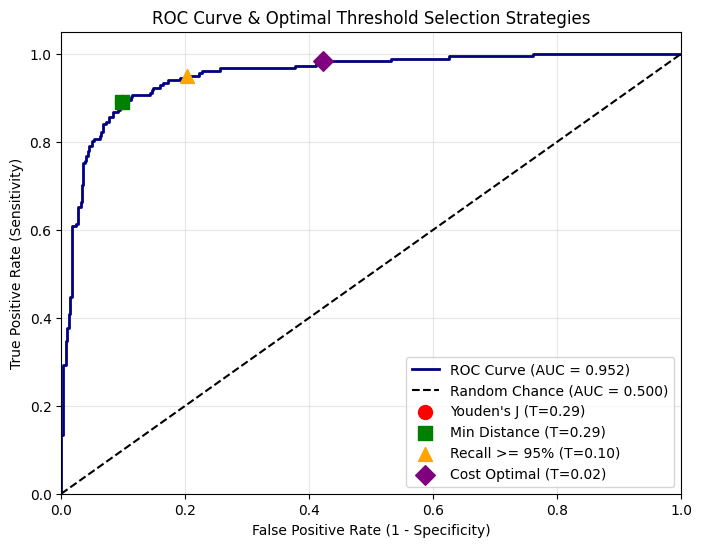

In [4]:
# -------------------------------------------------------------------
# Strategy 1: Youden's J Statistic
# Formula: J = TPR - FPR (or Sensitivity + Specificity - 1)
# -------------------------------------------------------------------
j_scores = tpr - fpr
idx_youden = np.argmax(j_scores)
opt_thresh_youden = thresholds[idx_youden]

print(f"[Strategy 1 - Youden's J]")
print(f"Optimal Threshold: {opt_thresh_youden:.4f} | TPR: {tpr[idx_youden]:.4f} | FPR: {fpr[idx_youden]:.4f}\n")

# -------------------------------------------------------------------
# Strategy 2: Shortest Distance to (0, 1) Corner
# Formula: d = sqrt((1 - TPR)^2 + FPR^2)
# -------------------------------------------------------------------
distances = np.sqrt((1 - tpr)**2 + fpr**2)
idx_dist = np.argmin(distances)
opt_thresh_dist = thresholds[idx_dist]

print(f"[Strategy 2 - Distance to (0,1)]")
print(f"Optimal Threshold: {opt_thresh_dist:.4f} | TPR: {tpr[idx_dist]:.4f} | FPR: {fpr[idx_dist]:.4f}\n")

# -------------------------------------------------------------------
# Strategy 3: Target Recall Constraint (e.g., Catch >= 95% of positive cases)
# -------------------------------------------------------------------
target_recall = 0.95
idx_recall = np.argmax(tpr >= target_recall)
opt_thresh_recall = thresholds[idx_recall]

print(f"[Strategy 3 - Target Recall >= {target_recall*100}%]")
print(f"Optimal Threshold: {opt_thresh_recall:.4f} | Actual Recall (TPR): {tpr[idx_recall]:.4f} | FPR: {fpr[idx_recall]:.4f}\n")

# -------------------------------------------------------------------
# Strategy 4: Target FPR Constraint (e.g., False Alarm Rate <= 5%)
# -------------------------------------------------------------------
target_max_fpr = 0.05
# Find the largest index where FPR <= target_max_fpr
idx_fpr = np.where(fpr <= target_max_fpr)[0][-1]
opt_thresh_fpr = thresholds[idx_fpr]

print(f"[Strategy 4 - Max FPR <= {target_max_fpr*100}%]")
print(f"Optimal Threshold: {opt_thresh_fpr:.4f} | TPR: {tpr[idx_fpr]:.4f} | Actual FPR: {fpr[idx_fpr]:.4f}\n")

# -------------------------------------------------------------------
# Strategy 5: Cost-Sensitive Optimization
# Scenario: Missing a fraud/disease (FN) costs $500. A false alarm (FP) costs $20.
# -------------------------------------------------------------------
cost_fn = 500
cost_fp = 20

# Calculate total costs for each threshold on test dataset
total_costs = []
P = np.sum(y_test == 1)
N = np.sum(y_test == 0)

for i, t in enumerate(thresholds):
    # FN = P - TP = P * (1 - TPR)
    # FP = N * FPR
    fn = P * (1 - tpr[i])
    fp = N * fpr[i]
    cost = (fn * cost_fn) + (fp * cost_fp)
    total_costs.append(cost)

idx_cost = np.argmin(total_costs)
opt_thresh_cost = thresholds[idx_cost]

print(f"[Strategy 5 - Business Cost Optimization]")
print(f"Optimal Threshold: {opt_thresh_cost:.4f} | Total Min Cost: ${total_costs[idx_cost]:,.2f}")
print(f"TPR: {tpr[idx_cost]:.4f} | FPR: {fpr[idx_cost]:.4f}\n")

# -------------------------------------------------------------------
# Plot the ROC Curve with Selected Strategy Points
# -------------------------------------------------------------------
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.3f})', color='navy', lw=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.500)')

# Plot markers
plt.scatter(fpr[idx_youden], tpr[idx_youden], color='red', s=100, zorder=5, 
            label=f"Youden's J (T={opt_thresh_youden:.2f})")
plt.scatter(fpr[idx_dist], tpr[idx_dist], color='green', s=100, marker='s', zorder=5, 
            label=f"Min Distance (T={opt_thresh_dist:.2f})")
plt.scatter(fpr[idx_recall], tpr[idx_recall], color='orange', s=100, marker='^', zorder=5, 
            label=f"Recall >= 95% (T={opt_thresh_recall:.2f})")
plt.scatter(fpr[idx_cost], tpr[idx_cost], color='purple', s=100, marker='D', zorder=5, 
            label=f"Cost Optimal (T={opt_thresh_cost:.2f})")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve & Optimal Threshold Selection Strategies')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()